# FIT5215 / FIT3181 Assignment 1 - Kaggle Starter Notebook

This notebook provides a complete, deliberately simple workflow: download the training data, load the hidden-label Kaggle test set, create a validation split, train a starter CNN, and write a valid Kaggle submission.

The starter notebook is intended to run in **Google Colab with a GPU runtime**. Improve the data augmentation, model architecture, optimization, and validation procedure for your own submission.

## Before you start

1. In Colab, select **Runtime → Change runtime type → GPU**.
2. Make your own copy of this notebook.
3. On the competition **Data** tab, download `test_set.zip` and upload it to the Colab Files pane. When extracted, it creates a `test_set` folder containing the `test_dataset` image folder and the sample submission template `my_solution.csv`.

   **If your computer automatically decompresses the file downloaded from Kaggle, compress the complete extracted `test_set` folder again, name the new archive `test_set.zip`, and upload that ZIP file to Colab.**

4. The labelled training set is downloaded separately from Google Drive. Use the [primary training archive](https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing), or manually switch to the [backup training archive](https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing) if the primary link is unavailable.

The release contains **9,466 labelled training images across 20 classes** and **11,681 unlabelled 64×64 test images**. The submission template contains the columns `ID,Label`. Use only the provided training labels and follow the assignment and competition rules.

In [1]:
%pip install -q "timm==1.0.15" "einops==0.8.1" "huggingface_hub>=0.34,<2" tqdm

import sys
import subprocess
from pathlib import Path

PE_CODE_REVISION = (
  "3e352cca660658d4b5c90f42a7808b11469e4c66"
)

PE_REPO = Path("/content/perception_models_pe_core")

if not PE_REPO.exists():
  subprocess.run(
    [
      "git",
      "clone",
      "--quiet",
      "https://github.com/facebookresearch/perception_models.git",
      str(PE_REPO)
    ],
    check=True
  )

subprocess.run(
  [
    "git",
    "-C",
    str(PE_REPO),
    "checkout",
    "--quiet",
    "--detach",
    PE_CODE_REVISION
  ],
  check=True
)

if str(PE_REPO) not in sys.path:
  sys.path.insert(0, str(PE_REPO))

print("PE source ready:", PE_REPO)
print("Source revision:", PE_CODE_REVISION)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 7.7 MB/s eta 0:00:00
PE source ready: /content/perception_models_pe_core
Source revision: 3e352cca660658d4b5c90f42a7808b11469e4c66


In [2]:
from __future__ import annotations

import copy
import os
import random
import zipfile
from pathlib import Path
import gc
import shutil
import time

from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download
from torch.utils.checkpoint import checkpoint as activation_checkpoint

import core.vision_encoder.pe as pe

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 2026
ROOT = Path('/content') if Path('/content').is_dir() else Path.cwd()
TRAIN_ARCHIVE = ROOT / 'Animals_Dataset.zip'
TRAIN_DIR = ROOT / 'FIT5215_Dataset'
TEST_ARCHIVE = ROOT / 'test_set.zip'
TEST_PACKAGE_DIR = ROOT / 'test_set'
TEST_DIR = TEST_PACKAGE_DIR / 'test_dataset'
SUBMISSION_TEMPLATE = TEST_PACKAGE_DIR / 'my_solution.csv'

def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working directory:', ROOT)
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type != 'cuda':
    print('Warning: training will be much slower without a GPU runtime.')

Working directory: /content
PyTorch: 2.11.0+cu128
Device: cuda


## 1. Download the labelled training set

Run the primary download below. If that link is unavailable, comment it out and uncomment the backup download. Both commands save the archive with the same filename.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Primary download
#!gdown --fuzzy 'https://drive.google.com/file/d/10Y65ykpja1t6UWt3imPPbZkqhe0kOPL9/view?usp=sharing' -O Animals_Dataset.zip

# Backup download: use this only if the primary link is unavailable.
#!gdown --fuzzy 'https://drive.google.com/file/d/1uc7uQ5myz7k74ZO460Q04B35_GekQeGi/view?usp=sharing' -O Animals_Dataset.zip

!cp "/content/drive/MyDrive/FIT3181/Animals_Dataset.zip" "/content/Animals_Dataset.zip"

!unzip -q -o "/content/Animals_Dataset.zip" -d "/content"

#!unzip -q -o Animals_Dataset.zip
assert TRAIN_DIR.is_dir(), f'Training folder not found: {TRAIN_DIR}'
print('Training data ready:', TRAIN_DIR)

Training data ready: /content/FIT5215_Dataset


## 2. Load the Kaggle test data and submission template

Upload `test_set.zip` to the Colab Files pane. It must extract into the same layout as the Kaggle download:

```text
test_set.zip
└── test_set/
    ├── test_dataset/
    │   ├── 00000_animal.jpeg
    │   └── ...
    └── my_solution.csv
```

**If your computer automatically decompresses the Kaggle download, compress the complete extracted `test_set` folder again, name the archive `test_set.zip`, and then upload it to Colab.** Keep the names and folder structure unchanged.

In [5]:
EXPECTED_TEST_IMAGES = 11_681

if not TEST_DIR.is_dir() or not SUBMISSION_TEMPLATE.is_file():
    assert TEST_ARCHIVE.is_file(), (
        'Upload test_set.zip to the Colab Files pane before continuing.'
    )
    with zipfile.ZipFile(TEST_ARCHIVE) as archive:
        archive.extractall(ROOT)

assert TEST_PACKAGE_DIR.is_dir(), (
    'The ZIP must contain a top-level folder named test_set.'
)
assert TEST_DIR.is_dir(), (
    'The test_set folder must contain the test_dataset image folder.'
)
test_paths = sorted(TEST_DIR.glob('*_animal.jpeg'))
test_ids = [int(path.name.split('_', 1)[0]) for path in test_paths]
assert len(test_paths) == EXPECTED_TEST_IMAGES, (
    f'Expected {EXPECTED_TEST_IMAGES:,} test images, found {len(test_paths):,}.'
)
assert test_ids == list(range(EXPECTED_TEST_IMAGES)), (
    'Test image IDs must run from 0 to 11680.'
)
assert SUBMISSION_TEMPLATE.is_file(), (
    'The test_set folder must contain my_solution.csv.'
)
submission_template = pd.read_csv(SUBMISSION_TEMPLATE)
assert submission_template.columns.tolist() == ['ID', 'Label']
assert submission_template['ID'].tolist() == test_ids
print(f'Test data ready: {len(test_paths):,} images')
display(submission_template.head())

Test data ready: 11,681 images


,ID,Label
0,0,birds
1,1,birds
2,2,birds
3,3,birds
4,4,birds


## 3. Build training, validation, and test datasets

The split is stratified so every class is represented in both training and validation. Training augmentation is intentionally mild because the Kaggle images are only 64×64. Validation and test preprocessing are deterministic.

In [6]:
VALIDATION_FRACTION = 0.15

EXPECTED_CLASS_NAMES = [
  'birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats',
  'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes',
  'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes',
  'spiders', 'vases',
]

CLASS_NAME_CORRECTIONS = {
  'butterfiles': 'butterflies'
}

from torchvision.transforms import InterpolationMode

INPUT_SIZE = 448

MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)

from PIL import ImageFilter, ImageOps

class RandomStyleVariation:
  def __call__(self, image):
    choice = random.random()

    # Keep the original appearance.
    if choice < 0.60:
      return image

    # Grayscale photograph.
    if choice < 0.75:
      return ImageOps.grayscale(image).convert("RGB")

    # Reduce the number of colour levels.
    if choice < 0.85:
      return ImageOps.posterize(image, bits=4)

    # Increase contrast.
    if choice < 0.90:
      return ImageOps.autocontrast(image, cutoff=1)

    # Create a simple sketch-like appearance.
    gray = ImageOps.grayscale(image)

    blurred = gray.filter(
      ImageFilter.GaussianBlur(radius=1.5)
    )

    gray_array = np.asarray(
      gray,
      dtype=np.float32
    )

    blurred_array = np.asarray(
      blurred,
      dtype=np.float32
    )

    sketch_array = (
      255.0 * gray_array / (blurred_array + 1.0)
    )

    sketch_array = np.clip(
      sketch_array,
      0,
      255
    ).astype(np.uint8)

    sketch = Image.fromarray(sketch_array)

    return ImageOps.autocontrast(
      sketch,
      cutoff=1
    ).convert("RGB")


train_transform = transforms.Compose([
  transforms.Resize(
    (64, 64),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  RandomStyleVariation(),
  transforms.RandomResizedCrop(
    INPUT_SIZE,
    scale=(0.75, 1.0),
    ratio=(0.85, 1.15),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.ColorJitter(
    brightness=0.10,
    contrast=0.10,
    saturation=0.10,
    hue=0.02
  ),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

evaluation_transform = transforms.Compose([
  transforms.Resize(
    (64, 64),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.Resize(
    (INPUT_SIZE, INPUT_SIZE),
    interpolation=InterpolationMode.BILINEAR,
    antialias=True
  ),
  transforms.ToTensor(),
  transforms.Normalize(MEAN, STD)
])

index_dataset = datasets.ImageFolder(TRAIN_DIR)

class_names = [
  CLASS_NAME_CORRECTIONS.get(name, name)
  for name in index_dataset.classes
]

if class_names != EXPECTED_CLASS_NAMES:
  raise RuntimeError(
    f'Unexpected training class order: {class_names}'
  )

targets = np.asarray(
  index_dataset.targets,
  dtype=np.int64
)

rng = np.random.default_rng(SEED)

train_indices = []
validation_indices = []

for class_index in range(len(class_names)):
  class_indices = np.flatnonzero(
    targets == class_index
  )

  rng.shuffle(class_indices)

  validation_count = max(
    1,
    int(
      round(
        len(class_indices)
        * VALIDATION_FRACTION
      )
    )
  )

  validation_indices.extend(
    class_indices[:validation_count].tolist()
  )

  train_indices.extend(
    class_indices[validation_count:].tolist()
  )

train_indices = sorted(train_indices)
validation_indices = sorted(validation_indices)

training_augmented = datasets.ImageFolder(
  TRAIN_DIR,
  transform=train_transform
)

training_evaluation = datasets.ImageFolder(
  TRAIN_DIR,
  transform=evaluation_transform
)

train_dataset = Subset(
  training_augmented,
  train_indices
)

train_evaluation_dataset = Subset(
  training_evaluation,
  train_indices
)

validation_dataset = Subset(
  training_evaluation,
  validation_indices
)

class KaggleTestDataset(Dataset):
  def __init__(self, paths: list[Path], transform):
    self.paths = paths
    self.transform = transform

  def __len__(self) -> int:
    return len(self.paths)

  def __getitem__(self, index: int):
    path = self.paths[index]

    test_id = int(
      path.name.split('_', 1)[0]
    )

    with Image.open(path) as image:
      tensor = self.transform(
        image.convert('RGB')
      )

    return tensor, test_id

test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

print('Classes:', class_names)

Classes: ['birds', 'bottles', 'breads', 'butterflies', 'cakes', 'cats', 'chickens', 'cows', 'dogs', 'ducks', 'elephants', 'fishes', 'handguns', 'horses', 'lions', 'lipsticks', 'seals', 'snakes', 'spiders', 'vases']


In [7]:
BATCH_SIZE = 2
NUM_WORKERS = 0
pin_memory = device.type == 'cuda'

loader_generator = torch.Generator().manual_seed(SEED)

def seed_worker(worker_id: int) -> None:
  worker_seed = torch.initial_seed() % (2**32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)

train_loader = DataLoader(
  train_dataset,
  batch_size=BATCH_SIZE,
  shuffle=True,
  generator=loader_generator,
  worker_init_fn=seed_worker,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

train_evaluation_loader = DataLoader(
  train_evaluation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

validation_loader = DataLoader(
  validation_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

print(f'Train: {len(train_dataset):,}')
print(f'Validation: {len(validation_dataset):,}')
print(f'Test: {len(test_dataset):,}')

Train: 8,047
Validation: 1,419
Test: 11,681


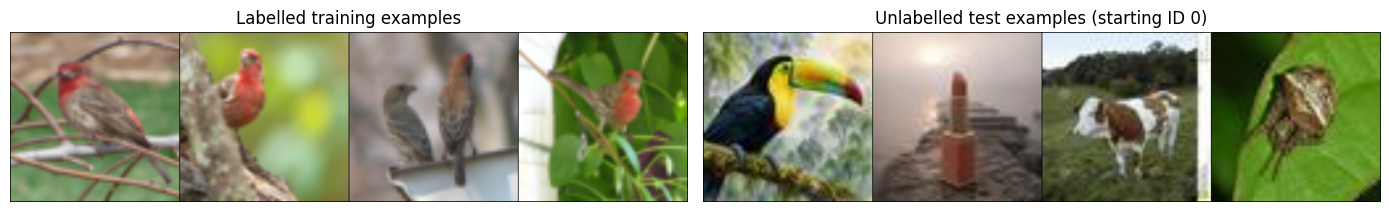

Example training label: birds


In [8]:
def denormalize(batch: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MEAN).view(1, 3, 1, 1)
    std = torch.tensor(STD).view(1, 3, 1, 1)
    return (batch.cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_evaluation_loader))
test_images, displayed_test_ids = next(iter(test_loader))
figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(make_grid(denormalize(images[:32]), nrow=8).permute(1, 2, 0))
axes[0].set_title('Labelled training examples')
axes[0].axis('off')
axes[1].imshow(make_grid(denormalize(test_images[:32]), nrow=8).permute(1, 2, 0))
axes[1].set_title(f'Unlabelled test examples (starting ID {int(displayed_test_ids[0])})')
axes[1].axis('off')
figure.tight_layout()
plt.show()
print('Example training label:', class_names[int(labels[0])])

## 4. Define a starter CNN

This compact network is a starting point, not a target solution. You are expected to make and justify your own improvements within the assignment rules.

In [9]:
BACKBONE_NAME = "facebook/PE-Core-G14-448"
PE_CONFIG_NAME = "PE-Core-G14-448"

PE_WEIGHT_REVISION = (
  "a6046680086f67d1f24d4b465a240de0578dfc0b"
)

RUN_NAME = "pe_core_g14_448_style_v1"

HEAD_DROPOUT = 0.20
ACCUMULATION_STEPS = 4

if device.type != "cuda":
  raise RuntimeError(
    "Select a GPU runtime before loading PE-Core Giant."
  )

AMP_DTYPE = (
  torch.bfloat16
  if torch.cuda.is_bf16_supported()
  else torch.float16
)

CHECKPOINT_DIR = ROOT / f"{RUN_NAME}_checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_DIR = (
  Path("/content/drive/MyDrive/FIT3181_models")
  / RUN_NAME
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)


class CheckpointedBlock(nn.Module):
  def __init__(self, block):
    super().__init__()
    self.block = block

  def forward(self, x, attn_mask=None):
    use_checkpoint = (
      self.training
      and torch.is_grad_enabled()
      and any(
        parameter.requires_grad
        for parameter in self.block.parameters()
      )
    )

    if use_checkpoint:
      return activation_checkpoint(
        self.block,
        x,
        attn_mask=attn_mask,
        use_reentrant=False
      )

    return self.block(
      x,
      attn_mask=attn_mask
    )


class PEClassifier(nn.Module):
  def __init__(self, num_classes):
    super().__init__()

    # Construct only the vision encoder.
    self.features = pe.VisionTransformer.from_config(
      PE_CONFIG_NAME,
      pretrained=False
    )

    weights_path = hf_hub_download(
      repo_id=BACKBONE_NAME,
      filename=f"{PE_CONFIG_NAME}.pt",
      revision=PE_WEIGHT_REVISION
    )

    # Load on CPU. Memory mapping reduces initial RAM pressure.
    state = torch.load(
      weights_path,
      map_location="cpu",
      weights_only=True,
      mmap=True
    )

    if "state_dict" in state:
      state = state["state_dict"]
    elif "weights" in state:
      state = state["weights"]

    state = {
      name.removeprefix("module."): value
      for name, value in state.items()
    }

    # The original checkpoint can contain both image and text weights.
    if any(name.startswith("visual.") for name in state):
      state = {
        name.removeprefix("visual."): value
        for name, value in state.items()
        if name.startswith("visual.")
      }

    # Fail immediately if any vision weights do not match.
    self.features.load_state_dict(
      state,
      strict=True
    )

    del state
    gc.collect()

    # Use our checkpoint wrappers rather than PE's built-in path.
    self.features.set_grad_checkpointing(False)

    self.features.transformer.resblocks = nn.ModuleList([
      CheckpointedBlock(block)
      for block in self.features.transformer.resblocks
    ])

    self.features.requires_grad_(False)
    self.encoder_trainable = False

    feature_dim = self.features.output_dim

    self.classifier = nn.Sequential(
      nn.LayerNorm(feature_dim),
      nn.Dropout(HEAD_DROPOUT),
      nn.Linear(feature_dim, num_classes)
    )

  def train(self, mode=True):
    super().train(mode)

    if not self.encoder_trainable:
      self.features.eval()

    return self

  def forward(self, images):
    if images.shape[-2:] != (INPUT_SIZE, INPUT_SIZE):
      raise ValueError(
        f"Expected {INPUT_SIZE}x{INPUT_SIZE}, "
        f"received {tuple(images.shape[-2:])}."
      )

    encoder_gradients = (
      torch.is_grad_enabled()
      and self.encoder_trainable
    )

    with torch.set_grad_enabled(encoder_gradients):
      with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE
      ):
        features = self.features(images)

    return self.classifier(features.float())


seed_everything(SEED)

model = PEClassifier(
  num_classes=len(class_names)
).to(device)

gpu = torch.cuda.get_device_properties(device)

print("Backbone:", BACKBONE_NAME)
print("GPU:", gpu.name)
print(
  "GPU memory:",
  round(gpu.total_memory / 2**30, 1),
  "GiB"
)
print("Mixed precision:", AMP_DTYPE)
print("Feature dimension:", model.features.output_dim)
print(
  "Transformer blocks:",
  len(model.features.transformer.resblocks)
)
print(
  "Encoder parameters:",
  f"{sum(p.numel() for p in model.features.parameters()):,}"
)
print(
  "Trainable parameters:",
  f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)
print("Classification head:")
print(model.classifier)

model.eval()

with torch.inference_mode():
  sample_images, _ = next(iter(validation_loader))
  sample_images = sample_images[:1].to(device)

  sample_logits = model(sample_images)

assert sample_logits.shape == (1, len(class_names))
assert torch.isfinite(sample_logits).all()

print("Forward check passed:", tuple(sample_logits.shape))

del sample_images, sample_logits
gc.collect()
torch.cuda.empty_cache()

PE-Core-G14-448.pt: reconstructing file:   0%|          |  0.00B / 9.68GB            

PE-Core-G14-448.pt: downloading bytes:           |  0.00B            

Backbone: facebook/PE-Core-G14-448
GPU: NVIDIA A100-SXM4-80GB
GPU memory: 79.3 GiB
Mixed precision: torch.bfloat16
Feature dimension: 1280
Transformer blocks: 50
Encoder parameters: 1,882,032,640
Trainable parameters: 28,180
Classification head:
Sequential(
  (0): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  (1): Dropout(p=0.2, inplace=False)
  (2): Linear(in_features=1280, out_features=20, bias=True)
)
Forward check passed: (1, 20)


## 5. Train and select the best validation checkpoint

Only validation performance is used for model selection. The Kaggle test set remains unlabelled and is used once for final prediction.

In [10]:
training_loss_function = nn.CrossEntropyLoss(
  label_smoothing=0.05
)

validation_loss_function = nn.CrossEntropyLoss(
  label_smoothing=0.0
)


def save_checkpoint(model, path, metadata):
  temporary_path = path.with_suffix(".tmp")

  torch.save(
    {
      "model_state": model.state_dict(),
      "backbone_name": BACKBONE_NAME,
      "class_names": list(class_names),
      "input_size": INPUT_SIZE,
      "mean": MEAN,
      "std": STD,
      "head_dropout": HEAD_DROPOUT,
      "validation_indices": list(validation_indices),
      **metadata
    },
    temporary_path
  )

  os.replace(temporary_path, path)

  drive_path = SAVE_DIR / path.name

  drive_temporary_path = (
    SAVE_DIR / (path.name + ".tmp")
  )

  shutil.copy2(
    path,
    drive_temporary_path
  )

  os.replace(
    drive_temporary_path,
    drive_path
  )


def load_checkpoint(model, path):
  checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=True
  )

  if checkpoint["backbone_name"] != BACKBONE_NAME:
    raise RuntimeError("Checkpoint backbone does not match.")

  if checkpoint["class_names"] != list(class_names):
    raise RuntimeError("Checkpoint class order does not match.")

  model.load_state_dict(
    checkpoint.pop("model_state"),
    strict=True
  )

  model.eval()
  gc.collect()

  return checkpoint


def run_epoch(
  model,
  loader,
  loss_function,
  optimizer=None,
  scaler=None,
  description=""
):
  training = optimizer is not None
  model.train(training)

  total_loss = 0.0
  total_correct = 0
  total_examples = 0
  accumulated_examples = 0

  trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
  ]

  if training:
    optimizer.zero_grad(set_to_none=True)

  progress = tqdm(
    loader,
    desc=description,
    leave=False
  )

  for batch_index, (images, labels) in enumerate(
    progress,
    start=1
  ):
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    labels = labels.to(
      device=device,
      dtype=torch.long,
      non_blocking=True
    )

    batch_size = labels.size(0)

    with torch.set_grad_enabled(training):
      logits = model(images)
      loss = loss_function(logits, labels)

      if not torch.isfinite(loss):
        raise RuntimeError(
          f"Non-finite loss during {description}."
        )

      if training:
        # Accumulate summed losses, then average gradients
        # over the actual number of images in the window.
        scaler.scale(loss * batch_size).backward()
        accumulated_examples += batch_size

        update_now = (
          batch_index % ACCUMULATION_STEPS == 0
          or batch_index == len(loader)
        )

        if update_now:
          scaler.unscale_(optimizer)

          for parameter in trainable_parameters:
            if parameter.grad is not None:
              parameter.grad.div_(accumulated_examples)

          torch.nn.utils.clip_grad_norm_(
            trainable_parameters,
            max_norm=5.0
          )

          scaler.step(optimizer)
          scaler.update()

          optimizer.zero_grad(set_to_none=True)
          accumulated_examples = 0

    total_loss += loss.item() * batch_size

    total_correct += (
      logits.argmax(dim=1) == labels
    ).sum().item()

    total_examples += batch_size

    progress.set_postfix(
      loss=f"{total_loss / total_examples:.4f}",
      accuracy=f"{total_correct / total_examples:.2%}"
    )

  return (
    total_loss / total_examples,
    total_correct / total_examples
  )


def fit(
  model,
  train_loader,
  validation_loader,
  optimizer,
  epochs,
  stage
):
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
  )

  scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(AMP_DTYPE == torch.float16)
  )

  paths = {
    "loss": CHECKPOINT_DIR / f"{stage}_best_loss.pt",
    "accuracy": CHECKPOINT_DIR / f"{stage}_best_accuracy.pt"
  }

  best_scores = {
    "loss": (float("inf"), float("inf")),
    "accuracy": (float("inf"), float("inf"))
  }

  best_results = {}
  history = []

  for epoch in range(1, epochs + 1):
    start_time = time.perf_counter()

    learning_rate = optimizer.param_groups[0]["lr"]

    train_loss, train_accuracy = run_epoch(
      model,
      train_loader,
      training_loss_function,
      optimizer=optimizer,
      scaler=scaler,
      description=f"{stage}: train {epoch}/{epochs}"
    )

    validation_loss, validation_accuracy = run_epoch(
      model,
      validation_loader,
      validation_loss_function,
      description=f"{stage}: validation {epoch}/{epochs}"
    )

    row = {
      "epoch": epoch,
      "train_loss": train_loss,
      "train_accuracy": train_accuracy,
      "validation_loss": validation_loss,
      "validation_accuracy": validation_accuracy,
      "learning_rate": learning_rate
    }

    history.append(row)

    # Both criteria are minimized.
    scores = {
      "loss": (
        validation_loss,
        -validation_accuracy
      ),
      "accuracy": (
        -validation_accuracy,
        validation_loss
      )
    }

    for criterion in ("loss", "accuracy"):
      if scores[criterion] < best_scores[criterion]:
        metadata = {
          "stage": stage,
          "epoch": epoch,
          "criterion": criterion,
          "validation_loss": validation_loss,
          "validation_accuracy": validation_accuracy
        }

        save_checkpoint(
          model,
          paths[criterion],
          metadata
        )

        best_scores[criterion] = scores[criterion]
        best_results[criterion] = metadata

    pd.DataFrame(history).to_csv(
      CHECKPOINT_DIR / f"{stage}_history.csv",
      index=False
    )

    elapsed_minutes = (
      time.perf_counter() - start_time
    ) / 60

    print(
      f"Epoch {epoch:02d}/{epochs:02d} | "
      f"train loss {train_loss:.4f}, "
      f"acc {train_accuracy:.2%} | "
      f"val CE {validation_loss:.4f}, "
      f"acc {validation_accuracy:.2%} | "
      f"lr {learning_rate:.7f} | "
      f"{elapsed_minutes:.1f} min"
    )

    scheduler.step()

# Save the final epoch separately from the best checkpoints.
  final_row = history[-1]

  paths["final"] = (
    CHECKPOINT_DIR / f"{stage}_final.pt"
  )

  final_metadata = {
    "stage": stage,
    "epoch": int(final_row["epoch"]),
    "criterion": "final",
    "validation_loss": final_row["validation_loss"],
    "validation_accuracy": final_row["validation_accuracy"]
  }

  save_checkpoint(
    model,
    paths["final"],
    final_metadata
  )

  best_results["final"] = final_metadata

  for criterion in ("loss", "accuracy"):
    result = best_results[criterion]

    print(
      f"Best by {criterion}: epoch {result['epoch']} | "
      f"val CE {result['validation_loss']:.4f} | "
      f"acc {result['validation_accuracy']:.2%}"
    )

  return (
    pd.DataFrame(history),
    paths,
    best_results
  )

In [11]:
BASE_CHECKPOINT = Path(
  "/content/drive/MyDrive/FIT3181_models/"
  "pe_core_g14_448/last8_best_accuracy.pt"
)

if not BASE_CHECKPOINT.is_file():
  raise FileNotFoundError(
    f"Saved PE checkpoint not found: {BASE_CHECKPOINT}"
  )

if "optimizer" in globals():
  del optimizer

model.zero_grad(set_to_none=True)
gc.collect()
torch.cuda.empty_cache()

baseline_metadata = load_checkpoint(
  model,
  BASE_CHECKPOINT
)

if list(baseline_metadata["validation_indices"]) != list(
  validation_indices
):
  raise RuntimeError(
    "The validation split differs from the saved checkpoint."
  )

if baseline_metadata["input_size"] != INPUT_SIZE:
  raise RuntimeError(
    "The input size differs from the saved checkpoint."
  )

if (
  tuple(baseline_metadata["mean"]) != tuple(MEAN)
  or tuple(baseline_metadata["std"]) != tuple(STD)
):
  raise RuntimeError(
    "Normalization differs from the saved checkpoint."
  )

baseline_loss, baseline_accuracy = run_epoch(
  model,
  validation_loader,
  validation_loss_function,
  description="Restored PE baseline"
)

print("Restored checkpoint:", BASE_CHECKPOINT)
print("Original epoch:", baseline_metadata["epoch"])
print(f"Baseline validation CE: {baseline_loss:.4f}")
print(f"Baseline validation accuracy: {baseline_accuracy:.2%}")
print("Head training skipped.")

Restored PE baseline:   0%|          | 0/355 [00:00<?, ?it/s]

Restored checkpoint: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448/last8_best_accuracy.pt
Original epoch: 3
Baseline validation CE: 0.0590
Baseline validation accuracy: 99.86%
Head training skipped.


In [12]:
FINE_TUNE_EPOCHS = 5
UNFREEZE_BLOCKS = 8

ENCODER_LEARNING_RATE = 2e-6
CLASSIFIER_LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4

if "baseline_metadata" not in globals():
  raise RuntimeError(
    "Run the checkpoint-restoration cell first."
  )

if "optimizer" in globals():
  del optimizer

model.zero_grad(set_to_none=True)
gc.collect()
torch.cuda.empty_cache()

print("Starting style experiment from:", BASE_CHECKPOINT)
print(f"Starting validation CE: {baseline_loss:.4f}")
print(
  "Starting validation accuracy:",
  f"{baseline_accuracy:.2%}"
)

# Freeze the encoder before selecting trainable layers.
model.features.requires_grad_(False)

blocks = model.features.transformer.resblocks

if not 1 <= UNFREEZE_BLOCKS <= len(blocks):
  raise ValueError("Invalid number of blocks to unfreeze.")

for block in blocks[-UNFREEZE_BLOCKS:]:
  block.requires_grad_(True)

# Train the output normalization, attention pool and projection.
model.features.ln_post.requires_grad_(True)
model.features.attn_pool.requires_grad_(True)
model.features.proj.requires_grad_(True)

model.classifier.requires_grad_(True)
model.encoder_trainable = True

encoder_parameters = [
  parameter
  for parameter in model.features.parameters()
  if parameter.requires_grad
]

print(
  "Unfrozen transformer blocks:",
  UNFREEZE_BLOCKS,
  "/",
  len(blocks)
)
print(
  "Trainable encoder parameters:",
  f"{sum(p.numel() for p in encoder_parameters):,}"
)
print(
  "Effective training batch size:",
  train_loader.batch_size * ACCUMULATION_STEPS
)

# Check that gradients reach the trainable encoder.
# This performs no optimizer update.
model.train()

check_images, check_labels = next(iter(validation_loader))

check_images = check_images[:1].to(
  device=device,
  dtype=torch.float32
)
check_labels = check_labels[:1].to(
  device=device,
  dtype=torch.long
)

check_logits = model(check_images)
check_loss = training_loss_function(
  check_logits,
  check_labels
)

if not torch.isfinite(check_loss):
  raise RuntimeError("Non-finite loss in gradient check.")

check_loss.backward()

probe_parameter = next(blocks[-1].parameters())

if (
  probe_parameter.grad is None
  or not torch.isfinite(probe_parameter.grad).all()
):
  raise RuntimeError(
    "Gradient check failed for the final encoder block."
  )

if any(
  parameter.grad is not None
  for parameter in blocks[0].parameters()
):
  raise RuntimeError(
    "The first encoder block should remain frozen."
  )

print("Encoder gradient check passed.")

model.zero_grad(set_to_none=True)

del check_images, check_labels, check_logits, check_loss
gc.collect()
torch.cuda.empty_cache()

optimizer = torch.optim.AdamW(
  [
    {
      "params": encoder_parameters,
      "lr": ENCODER_LEARNING_RATE
    },
    {
      "params": model.classifier.parameters(),
      "lr": CLASSIFIER_LEARNING_RATE
    }
  ],
  weight_decay=WEIGHT_DECAY
)

seed_everything(SEED)
loader_generator.manual_seed(SEED)

fine_history, fine_paths, fine_results = fit(
  model,
  train_loader,
  validation_loader,
  optimizer,
  epochs=FINE_TUNE_EPOCHS,
  stage=f"last{UNFREEZE_BLOCKS}"
)

del optimizer
model.zero_grad(set_to_none=True)
gc.collect()
torch.cuda.empty_cache()

# Initial submission candidate: best fine-tuning accuracy.
SELECTION_CRITERION = "accuracy"

fine_best_checkpoint = fine_paths[SELECTION_CRITERION]
fine_metadata = fine_results[SELECTION_CRITERION]

fine_best_epoch = fine_metadata["epoch"]
fine_validation_loss = fine_metadata["validation_loss"]
fine_validation_accuracy = fine_metadata["validation_accuracy"]

selected_checkpoint = fine_best_checkpoint

selected_metadata = load_checkpoint(
  model,
  selected_checkpoint
)

selected_stage = selected_metadata["stage"]
selected_epoch = selected_metadata["epoch"]
validation_loss = selected_metadata["validation_loss"]
validation_accuracy = selected_metadata["validation_accuracy"]

print("\nSaved fine-tuning candidates:")

for criterion in ("accuracy", "loss", "final"):
  result = fine_results[criterion]

  print(
    f"{criterion}: epoch {result['epoch']} | "
    f"val CE {result['validation_loss']:.4f} | "
    f"accuracy {result['validation_accuracy']:.2%}"
  )

print("\nSelected checkpoint:", selected_checkpoint)
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)
print(f"Validation CE: {validation_loss:.4f}")
print(f"Validation accuracy: {validation_accuracy:.2%}")

Starting style experiment from: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448/last8_best_accuracy.pt
Starting validation CE: 0.0590
Starting validation accuracy: 99.86%
Unfrozen transformer blocks: 8 / 50
Trainable encoder parameters: 326,179,840
Effective training batch size: 8
Encoder gradient check passed.


last8: train 1/5:   0%|          | 0/4024 [00:00<?, ?it/s]

last8: validation 1/5:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 01/05 | train loss 0.3552, acc 99.35% | val CE 0.0581, acc 99.86% | lr 0.0000020 | 14.2 min


last8: train 2/5:   0%|          | 0/4024 [00:00<?, ?it/s]

...

last8: validation 4/5:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 04/05 | train loss 0.3478, acc 99.57% | val CE 0.0578, acc 99.86% | lr 0.0000013 | 15.6 min


last8: train 5/5:   0%|          | 0/4024 [00:00<?, ?it/s]

last8: validation 5/5:   0%|          | 0/355 [00:00<?, ?it/s]

Epoch 05/05 | train loss 0.3419, acc 99.73% | val CE 0.0580, acc 99.79% | lr 0.0000011 | 13.0 min
Best by loss: epoch 4 | val CE 0.0578 | acc 99.86%
Best by accuracy: epoch 4 | val CE 0.0578 | acc 99.86%

Saved fine-tuning candidates:
accuracy: epoch 4 | val CE 0.0578 | accuracy 99.86%
loss: epoch 4 | val CE 0.0578 | accuracy 99.86%
final: epoch 5 | val CE 0.0580 | accuracy 99.79%

Selected checkpoint: /content/pe_core_g14_448_style_v1_checkpoints/last8_best_accuracy.pt
Selected stage: last8
Selected epoch: 4
Validation CE: 0.0578
Validation accuracy: 99.86%


In [13]:
# Checkpoints were already copied to SAVE_DIR during training.
# Copy the completed training history as well.

for history_path in CHECKPOINT_DIR.glob("*_history.csv"):
  shutil.copy2(
    history_path,
    SAVE_DIR / history_path.name
  )

print("Experiment folder:", SAVE_DIR)

for criterion in ("accuracy", "loss", "final"):
  saved_path = SAVE_DIR / fine_paths[criterion].name

  if not saved_path.is_file():
    raise FileNotFoundError(
      f"Missing Drive checkpoint: {saved_path}"
    )

  result = fine_results[criterion]

  print(
    f"{criterion}: epoch {result['epoch']} | "
    f"val CE {result['validation_loss']:.4f} | "
    f"accuracy {result['validation_accuracy']:.2%}"
  )

CHECKPOINT_PATH = SAVE_DIR / selected_checkpoint.name

print("\nSelected Drive checkpoint:", CHECKPOINT_PATH)

Experiment folder: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448_style_v1
accuracy: epoch 4 | val CE 0.0578 | accuracy 99.86%
loss: epoch 4 | val CE 0.0578 | accuracy 99.86%
final: epoch 5 | val CE 0.0580 | accuracy 99.79%

Selected Drive checkpoint: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448_style_v1/last8_best_accuracy.pt


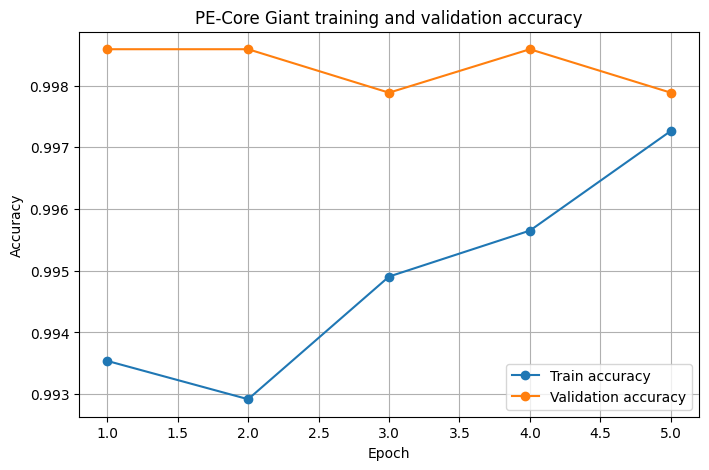

In [14]:
full_history = fine_history.copy()

plt.figure(figsize=(8, 5))

plt.plot(
  full_history["epoch"],
  full_history["train_accuracy"],
  marker="o",
  label="Train accuracy"
)

plt.plot(
  full_history["epoch"],
  full_history["validation_accuracy"],
  marker="o",
  label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("PE-Core Giant training and validation accuracy")
plt.legend()
plt.grid(True)
plt.show()

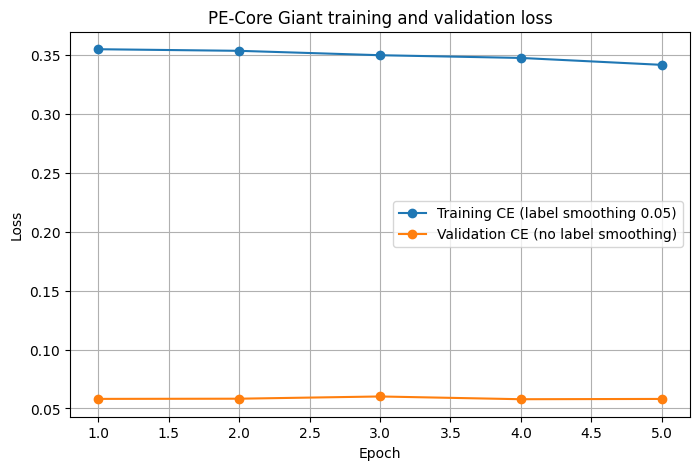

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
  full_history["epoch"],
  full_history["train_loss"],
  marker="o",
  label="Training CE (label smoothing 0.05)"
)

plt.plot(
  full_history["epoch"],
  full_history["validation_loss"],
  marker="o",
  label="Validation CE (no label smoothing)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PE-Core Giant training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

## 6. Predict the test set and create `submission.csv`

Kaggle expects exactly 11,681 rows with the string columns `ID,Label`. Prediction IDs are carried through the data loader and merged into the public template, so batching cannot silently reorder the submission.

In [16]:
if not selected_checkpoint.is_file():
  raise FileNotFoundError(
    f"Checkpoint not found: {selected_checkpoint}"
  )

test_dataset = KaggleTestDataset(
  test_paths,
  evaluation_transform
)

test_loader = DataLoader(
  test_dataset,
  batch_size=BATCH_SIZE * 2,
  shuffle=False,
  num_workers=NUM_WORKERS,
  pin_memory=pin_memory
)

selected_metadata = load_checkpoint(
  model,
  selected_checkpoint
)

selected_stage = selected_metadata["stage"]
selected_epoch = selected_metadata["epoch"]
validation_loss = selected_metadata["validation_loss"]
validation_accuracy = selected_metadata["validation_accuracy"]

model.eval()

print("Loaded checkpoint:", selected_checkpoint)
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)


@torch.inference_mode()
def collect_probabilities(model, loader, description):
  model.eval()

  all_probabilities = []
  all_keys = []

  for images, keys in tqdm(
    loader,
    desc=description
  ):
    images = images.to(
      device=device,
      dtype=torch.float32,
      non_blocking=True
    )

    logits = model(images)
    probabilities = torch.softmax(
      logits.float(),
      dim=1
    )

    if not torch.isfinite(probabilities).all():
      raise RuntimeError(
        "Predictions contain non-finite probabilities."
      )

    all_probabilities.append(
      probabilities.cpu().numpy()
    )
    all_keys.append(
      keys.cpu().numpy()
    )

  return (
    np.concatenate(all_probabilities, axis=0),
    np.concatenate(all_keys, axis=0)
  )


validation_probabilities, validation_labels = (
  collect_probabilities(
    model,
    validation_loader,
    "Validation predictions"
  )
)

test_probabilities, probability_test_ids = (
  collect_probabilities(
    model,
    test_loader,
    "Test predictions"
  )
)

if test_probabilities.shape != (
  EXPECTED_TEST_IMAGES,
  len(class_names)
):
  raise RuntimeError(
    "Unexpected test probability shape."
  )

validation_predictions = (
  validation_probabilities.argmax(axis=1)
)

correct = int(
  (validation_predictions == validation_labels).sum()
)

print(
  f"Validation accuracy: "
  f"{correct / len(validation_labels):.2%} "
  f"({correct}/{len(validation_labels)})"
)

validation_image_paths = [
  str(
    Path(index_dataset.samples[index][0])
    .relative_to(TRAIN_DIR)
  )
  for index in validation_indices
]

PROBABILITY_PATH = ROOT / (
  f"{RUN_NAME}_{selected_checkpoint.stem}_probabilities.npz"
)

np.savez_compressed(
  PROBABILITY_PATH,
  class_names=np.asarray(class_names),
  validation_probabilities=validation_probabilities,
  validation_labels=validation_labels,
  validation_indices=np.asarray(validation_indices),
  validation_paths=np.asarray(validation_image_paths),
  test_probabilities=test_probabilities,
  test_ids=probability_test_ids,
  backbone_name=np.asarray(BACKBONE_NAME),
  selected_stage=np.asarray(selected_stage),
  selected_epoch=np.asarray(selected_epoch),
  source_revision=np.asarray(PE_CODE_REVISION),
  pretrained_revision=np.asarray(PE_WEIGHT_REVISION)
)

shutil.copy2(
  PROBABILITY_PATH,
  SAVE_DIR / PROBABILITY_PATH.name
)

print("Probabilities saved:", PROBABILITY_PATH)
print("Drive copy:", SAVE_DIR / PROBABILITY_PATH.name)

Loaded checkpoint: /content/pe_core_g14_448_style_v1_checkpoints/last8_best_accuracy.pt
Selected stage: last8
Selected epoch: 4


Validation predictions:   0%|          | 0/355 [00:00<?, ?it/s]

Test predictions:   0%|          | 0/2921 [00:00<?, ?it/s]

Validation accuracy: 99.86% (1417/1419)
Probabilities saved: /content/pe_core_g14_448_style_v1_last8_best_accuracy_probabilities.npz
Drive copy: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448_style_v1/pe_core_g14_448_style_v1_last8_best_accuracy_probabilities.npz


In [17]:
predicted_ids = probability_test_ids.tolist()

predicted_indices = (
  test_probabilities.argmax(axis=1).tolist()
)

prediction_frame = pd.DataFrame({
  "ID": predicted_ids,
  "Label": [
    class_names[index]
    for index in predicted_indices
  ]
})

if prediction_frame["ID"].duplicated().any():
  raise RuntimeError(
    "Predictions contain duplicate IDs."
  )

if set(prediction_frame["Label"]) - set(EXPECTED_CLASS_NAMES):
  raise RuntimeError(
    "Predictions contain an invalid class label."
  )

if set(prediction_frame["ID"]) != set(submission_template["ID"]):
  raise RuntimeError(
    "Prediction IDs do not match the template."
  )

submission = submission_template[["ID"]].merge(
  prediction_frame,
  on="ID",
  how="left",
  sort=False,
  validate="one_to_one"
)

if submission.columns.tolist() != ["ID", "Label"]:
  raise RuntimeError(
    "Submission must contain exactly ID,Label."
  )

if (
  len(submission) != EXPECTED_TEST_IMAGES
  or submission["Label"].isna().any()
):
  raise RuntimeError(
    "Submission rows do not match the test set."
  )

if submission["ID"].tolist() != list(range(EXPECTED_TEST_IMAGES)):
  raise RuntimeError(
    "Submission IDs are not ordered from 0 to 11680."
  )

SUBMISSION_PATH = ROOT / (
  f"{RUN_NAME}_{selected_checkpoint.stem}_submission.csv"
)

submission.to_csv(
  SUBMISSION_PATH,
  index=False
)

shutil.copy2(
  SUBMISSION_PATH,
  SAVE_DIR / SUBMISSION_PATH.name
)

print("Submission:", SUBMISSION_PATH)
print("Drive copy:", SAVE_DIR / SUBMISSION_PATH.name)
print("Rows:", len(submission))
print("Selected stage:", selected_stage)
print("Selected epoch:", selected_epoch)

display(submission.head())
display(
  submission["Label"].value_counts().sort_index()
)

Submission: /content/pe_core_g14_448_style_v1_last8_best_accuracy_submission.csv
Drive copy: /content/drive/MyDrive/FIT3181_models/pe_core_g14_448_style_v1/pe_core_g14_448_style_v1_last8_best_accuracy_submission.csv
Rows: 11681
Selected stage: last8
Selected epoch: 4


,ID,Label
0,0,birds
1,1,lipsticks
2,2,cows
3,3,spiders
4,4,dogs


,count
Label,
birds,173
bottles,318
breads,312
butterflies,940
cakes,411
cats,976
chickens,917
cows,1056
dogs,801


In [18]:
prediction_summary = (
  submission["Label"]
  .value_counts()
  .rename_axis("Class")
  .reset_index(name="Count")
)

prediction_summary["Percentage"] = (
  prediction_summary["Count"]
  / len(submission)
  * 100
).round(2)

display(prediction_summary)

,Class,Count,Percentage
0,spiders,1199,10.26
1,elephants,1112,9.52
2,cows,1056,9.04
3,cats,976,8.36
4,butterflies,940,8.05
5,chickens,917,7.85
6,dogs,801,6.86
7,horses,715,6.12
8,vases,468,4.01
9,cakes,411,3.52


## 7. Submit and improve

Download `submission.csv`, open your cohort's Kaggle competition, choose **Submit Predictions**, and upload the CSV. Do not upload the unchanged `my_solution.csv` placeholder.

Useful next experiments include stronger but still mild augmentation, deeper model architectures, regularization, learning-rate schedules, class-balanced sampling, and permitted pretrained models. Keep the validation split fixed while comparing experiments, and preserve the exact test IDs and canonical string labels.

In [19]:
try:
    from google.colab import files
    files.download(str(SUBMISSION_PATH))
except ImportError:
    print(f'Not running in Colab. Submission is saved at {SUBMISSION_PATH}.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

folders = [
  Path("/content/pe_core_g14_448_checkpoints"),
  Path("/content/drive/MyDrive/FIT3181_models/pe_core_g14_448")
]

for folder in folders:
  print(f"\n{folder}")

  checkpoints = sorted(folder.glob("*.pt"))

  if not checkpoints:
    print("No checkpoints found here.")

  for path in checkpoints:
    print(path.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

/content/pe_core_g14_448_checkpoints
No checkpoints found here.

/content/drive/MyDrive/FIT3181_models/pe_core_g14_448
last8_best_accuracy.pt
